<a href="https://colab.research.google.com/github/nurinnuhaa4/20262R0136DATA30200/blob/main/notebooks/02_video_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

# Original extracted frames (30 FPS)
DATA_DIR = Path(
    "/content/drive/MyDrive/HOI_Project/extracted_frames"
)

# Output directory for processed frames (15 FPS)
PROCESSING_DIR = Path(
    "/content/drive/MyDrive/HOI_Project/processed_frames"
)

# Six official videos
video_ids = [
    "easy_01",
    "easy_02",
    "normal_01",
    "normal_02",
    "hard_01",
    "hard_02"
]

print("Original frames:", DATA_DIR)
print("Processing output:", PROCESSING_DIR)

Original frames: /content/drive/MyDrive/HOI_Project/extracted_frames
Processing output: /content/drive/MyDrive/HOI_Project/processed_frames


In [3]:
for video_id in video_ids:

    frames_dir = DATA_DIR / video_id / "frames"
    frames = sorted(frames_dir.glob("*.jpg"))

    print(f"{video_id}: {len(frames)} frames")

easy_01: 131 frames
easy_02: 451 frames
normal_01: 321 frames
normal_02: 331 frames
hard_01: 601 frames
hard_02: 481 frames


In [4]:
for video_id in video_ids:

    output_dir = PROCESSING_DIR / video_id / "frames"

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

print("All processing folders created")

for video_id in video_ids:
    output_dir = PROCESSING_DIR / video_id / "frames"
    print(video_id, output_dir.exists())

All processing folders created
easy_01 True
easy_02 True
normal_01 True
normal_02 True
hard_01 True
hard_02 True


In [5]:
import cv2

for video_id in video_ids:

    original_dir = DATA_DIR / video_id / "frames"
    output_dir = PROCESSING_DIR / video_id / "frames"

    original_frames = sorted(original_dir.glob("*.jpg"))

    for i in range(0, len(original_frames), 2):

        source_path = original_frames[i]
        output_path = output_dir / source_path.name

        image = cv2.imread(str(source_path))

        cv2.imwrite(str(output_path), image)

    print(
        f"{video_id}: "
        f"{len(original_frames)} original -> "
        f"{len(list(output_dir.glob('*.jpg')))} processed"
    )

easy_01: 131 original -> 66 processed
easy_02: 451 original -> 226 processed
normal_01: 321 original -> 161 processed
normal_02: 331 original -> 166 processed
hard_01: 601 original -> 301 processed
hard_02: 481 original -> 241 processed


In [6]:
import pandas as pd

ORIGINAL_FPS = 30
PROCESSING_FPS = 15

for video_id in video_ids:

    original_dir = DATA_DIR / video_id / "frames"
    processed_dir = PROCESSING_DIR / video_id / "frames"

    processed_frames = sorted(processed_dir.glob("*.jpg"))

    metadata = []

    for frame_path in processed_frames:

        original_frame_idx = int(frame_path.stem)

        metadata.append({
            "processed_frame": frame_path.name,
            "original_frame_idx": original_frame_idx,
            "timestamp_sec": original_frame_idx / ORIGINAL_FPS,
            "original_fps": ORIGINAL_FPS,
            "processing_fps": PROCESSING_FPS
        })

    df_metadata = pd.DataFrame(metadata)

    csv_path = PROCESSING_DIR / video_id / "frame_metadata.csv"

    df_metadata.to_csv(csv_path, index=False)

    print(f"{video_id}: metadata saved ({len(df_metadata)} rows)")

easy_01: metadata saved (66 rows)
easy_02: metadata saved (226 rows)
normal_01: metadata saved (161 rows)
normal_02: metadata saved (166 rows)
hard_01: metadata saved (301 rows)
hard_02: metadata saved (241 rows)


In [7]:
metadata_path = PROCESSING_DIR / "easy_01" / "frame_metadata.csv"

df = pd.read_csv(metadata_path)

display(df.head(10))

,processed_frame,original_frame_idx,timestamp_sec,original_fps,processing_fps
0,000000.jpg,0,0.000000,30,15
1,000002.jpg,2,0.066667,30,15
2,000004.jpg,4,0.133333,30,15
3,000006.jpg,6,0.200000,30,15
4,000008.jpg,8,0.266667,30,15
5,000010.jpg,10,0.333333,30,15
6,000012.jpg,12,0.400000,30,15
7,000014.jpg,14,0.466667,30,15
8,000016.jpg,16,0.533333,30,15
9,000018.jpg,18,0.600000,30,15


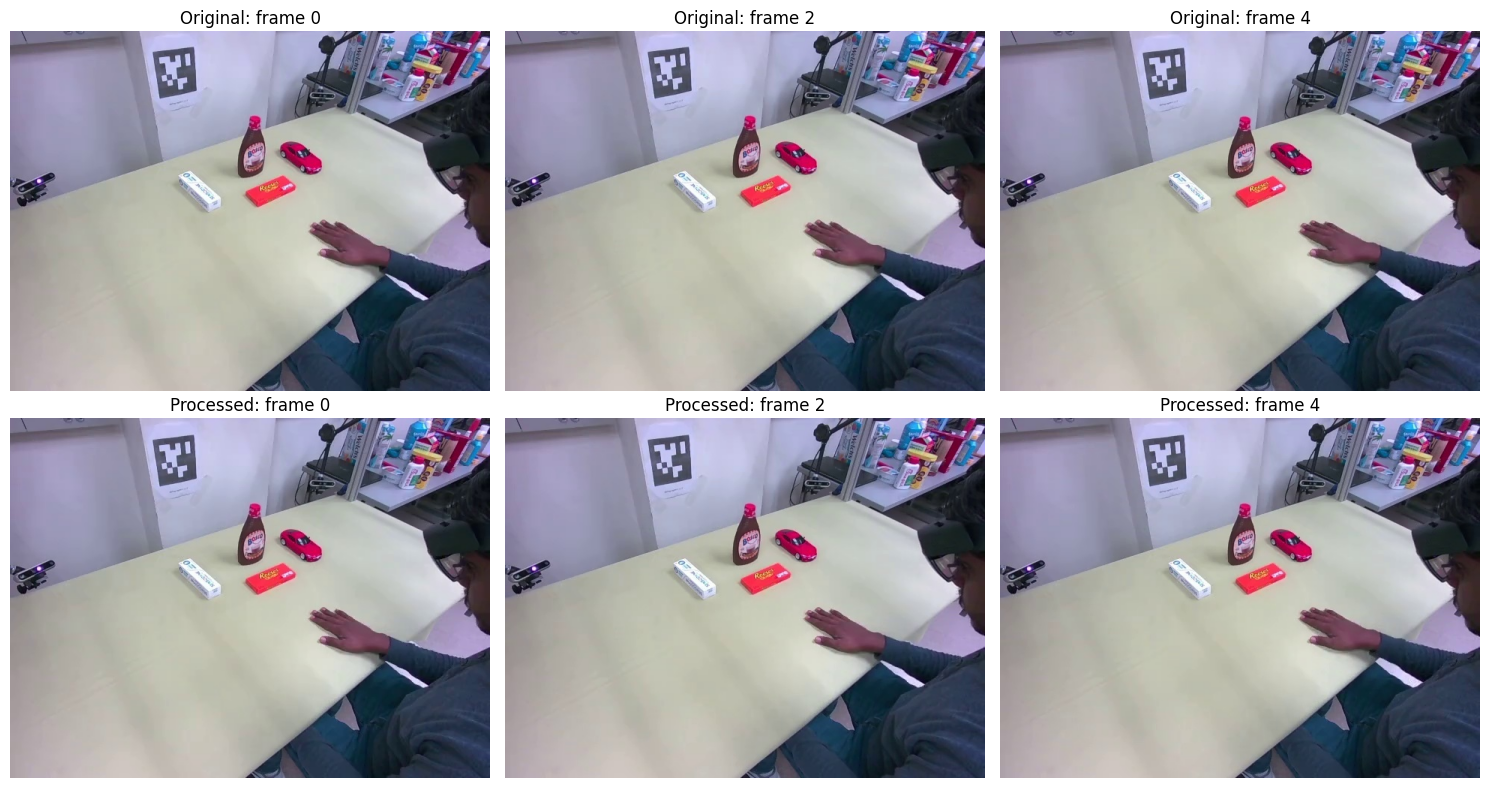

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

video_id = "easy_01"

original_dir = DATA_DIR / video_id / "frames"
processed_dir = PROCESSING_DIR / video_id / "frames"

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sample_indices = [0, 2, 4]

for col, idx in enumerate(sample_indices):

    original_path = original_dir / f"{idx:06d}.jpg"
    processed_path = processed_dir / f"{idx:06d}.jpg"

    original_img = Image.open(original_path)
    processed_img = Image.open(processed_path)

    axes[0, col].imshow(original_img)
    axes[0, col].set_title(f"Original: frame {idx}")

    axes[1, col].imshow(processed_img)
    axes[1, col].set_title(f"Processed: frame {idx}")

    axes[0, col].axis("off")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()